<a href="https://colab.research.google.com/github/yashikasgh/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yashikasgh/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

### 1. Ranked actions + reason codes

#### Ranking approach

I will use the Week-4 rule-based score to create the initial review queue. In my Week-5 evaluation, this baseline performed better than Logistic Regression on the client-grouped test set at Precision@20 and Precision@50. Therefore, the current evidence does not justify replacing the baseline with the learned model.

Each page receives a score based on three observable signals:

- **STALE (40 points):** `days_since_last_update` is at least 180.
- **HIGH_VISIBILITY (40 points):** `impressions_90d` is at or above the dataset median.
- **LOW_CTR (20 points):** `ctr` is below the dataset median.

Pages are ranked by score, from highest to lowest. Pages scoring 80–100 are placed in the first review tier, pages scoring 40–60 in the second tier, and pages scoring 0–20 in the monitoring tier. These tiers prioritize human attention; they do not automatically prescribe a content change.

#### Archetype-to-action mapping

- **High score, stale and high visibility:** Review for a possible refresh; verify search intent, factual accuracy, and current performance first.
- **High visibility and low CTR:** Review the title, description, search intent match, and result presentation.
- **Stale but low visibility:** Inspect indexing, relevance, demand, and content quality before deciding whether updating is worthwhile.
- **Low score:** Monitor rather than automatically editing or pruning the page.

#### Decay and refresh insight

The research paper reports associations between content age/freshness and observed growth or decline. These patterns can help prioritize review, but they do not prove that refreshing an individual page will improve traffic. A human reviewer should consider page purpose, demand, seasonality, accuracy, and business value before choosing an action.

In [4]:
import os
import pandas as pd
import numpy as np

# Find the uploaded FlyRank CSV
csv_path = "/content/content_refresh_anonymized.csv"

if not os.path.exists(csv_path):
    csv_matches = []
    for root, dirs, files in os.walk("/content"):
        for file in files:
            if file == "content_refresh_anonymized.csv":
                csv_matches.append(os.path.join(root, file))

    if not csv_matches:
        raise FileNotFoundError(
            "Could not find content_refresh_anonymized.csv. "
            "Upload the FlyRank CSV to Colab first."
        )
    csv_path = csv_matches[0]

playbook_df = pd.read_csv(csv_path)

required_cols = [
    "content_id",
    "impressions_90d",
    "ctr",
    "days_since_last_update",
]

missing_cols = [c for c in required_cols if c not in playbook_df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# Use consistent thresholds derived from the dataset
impression_median = playbook_df["impressions_90d"].median()
ctr_median = playbook_df["ctr"].median()

playbook_df["stale"] = (
    playbook_df["days_since_last_update"] >= 180
)
playbook_df["high_visibility"] = (
    playbook_df["impressions_90d"] >= impression_median
)
playbook_df["low_ctr"] = (
    playbook_df["ctr"] < ctr_median
)

playbook_df["baseline_score"] = (
    40 * playbook_df["stale"].astype(int)
    + 40 * playbook_df["high_visibility"].astype(int)
    + 20 * playbook_df["low_ctr"].astype(int)
)

# Explainable reason codes
def get_reason_codes(row):
    reasons = []
    if row["stale"]:
        reasons.append("STALE")
    if row["high_visibility"]:
        reasons.append("HIGH_VISIBILITY")
    if row["low_ctr"]:
        reasons.append("LOW_CTR")
    return "|".join(reasons) if reasons else "NO_PRIORITY_SIGNAL"

def get_action(score):
    if score >= 80:
        return "PRIORITY_HUMAN_REVIEW"
    elif score >= 40:
        return "SECONDARY_HUMAN_REVIEW"
    return "MONITOR"

playbook_df["reason_codes"] = playbook_df.apply(
    get_reason_codes, axis=1
)
playbook_df["recommended_action"] = (
    playbook_df["baseline_score"].apply(get_action)
)

# Rank deterministically; content_id is only a tie-breaker
playbook_df = playbook_df.sort_values(
    ["baseline_score", "content_id"],
    ascending=[False, True]
).reset_index(drop=True)

playbook_df.insert(
    0, "review_rank", np.arange(1, len(playbook_df) + 1)
)

queue_cols = [
    "review_rank",
    "content_id",
    "baseline_score",
    "recommended_action",
    "reason_codes",
    "days_since_last_update",
    "impressions_90d",
    "ctr",
]

ranked_queue = playbook_df[queue_cols].copy()

print("Dataset rows:", len(ranked_queue))
print("Impressions median:", impression_median)
print("CTR median:", ctr_median)

print("\nAction counts:")
display(ranked_queue["recommended_action"].value_counts().to_frame("pages"))

print("\nTop 10 pages for human review:")
display(ranked_queue.head(10))

Dataset rows: 30000
Impressions median: 731.0
CTR median: 0.07

Action counts:


,pages
recommended_action,
SECONDARY_HUMAN_REVIEW,15151
MONITOR,14834
PRIORITY_HUMAN_REVIEW,15



Top 10 pages for human review:


,review_rank,content_id,baseline_score,recommended_action,reason_codes,days_since_last_update,impressions_90d,ctr
0,1,content_5feee3994adb,100,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY|LOW_CTR,194,7812,0.01
1,2,content_b16bd7307b39,100,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY|LOW_CTR,194,4590,0.00
2,3,content_0a91db491d14,80,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY,193,13299,0.49
3,4,content_1bfaa38ff26c,80,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY,194,25715,0.23
4,5,content_72496874f806,80,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY,301,821,0.24
5,6,content_7368877ea310,80,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY,194,59472,0.13
6,7,content_77d4d5930e5e,80,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY,194,828,0.24
7,8,content_7f116ae1f6f5,80,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY,301,954,0.42
8,9,content_928af3e22c80,80,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY,193,1697,0.12
9,10,content_bdbec75c1148,80,PRIORITY_HUMAN_REVIEW,STALE|HIGH_VISIBILITY,194,1316,0.15


### Intended use and Limits

The action playbook is a decision-support tool for prioritizing content pages for human review. It ranks pages using three transparent signals: content staleness, search visibility, and click-through rate (CTR). Each page receives reason codes so that a reviewer can understand why it was prioritized.

The highest-priority pages should be reviewed first, followed by the secondary-review queue. Pages assigned to monitoring should not automatically be considered successful or problem-free; they simply have fewer priority signals under the current rules.

### Limits and assumptions

- The score is a rule-based heuristic, not a calibrated probability of traffic decline or future growth.
- The thresholds depend on this dataset: the impressions and CTR medians are 731 and 0.07, respectively. They may not transfer to other websites or time periods.
- A high score does not prove that refreshing a page will improve traffic, rankings, or conversions.
- Low CTR can have multiple explanations, including search intent, title and description quality, ranking position, and the search results page.
- The model does not independently verify factual accuracy, legal or regulatory compliance, content quality, or business value.
- The dataset's trend label and observation windows have not been fully verified for temporal leakage. Model performance should therefore be interpreted cautiously.
- Final decisions require a human reviewer who can examine the page, its purpose, available evidence, and the cost of making changes.

### Cost and value considerations

Review time is limited, so the queue should help reviewers focus on pages with multiple actionable signals. Before editing a page, estimate the effort required, the potential value of improving it, and the risk of changing useful content. Start with a small, documented review batch and measure outcomes before expanding the process. Do not assume that a higher score automatically means a higher financial return.

## 3. Human review + the no-go list

### Human review checklist

Before acting on a recommendation, a reviewer should:

1. Open the page and verify that its content is still accurate, useful, and relevant to the intended audience.
2. Check whether the last-update date reflects a meaningful content change or only a technical modification.
3. For high-visibility pages, inspect impressions, CTR, and average search position together rather than interpreting CTR in isolation.
4. Review the search intent, title, meta description, internal links, and competing pages where relevant.
5. Identify outdated claims, missing information, broken links, and opportunities to improve clarity.
6. Estimate the effort and business value of the proposed change.
7. Record the decision, reason, reviewer, and review date. If no change is appropriate, document why.

### No-go list: decisions that must not be automated

- Do not publish or overwrite content automatically based only on the score.
- Do not delete, redirect, or deindex pages solely because they have low visibility or a low score.
- Do not invent facts, statistics, citations, legal claims, or product details to make a page appear more complete.
- Do not change legally sensitive, safety-critical, financial, or regulated content without appropriate expert review.
- Do not treat correlation between freshness and content performance as proof that refreshing a page causes improvement.
- Do not expose client identities, private URLs, search queries, credentials, or other confidential information in public reports.
- Do not use the ranking as the sole basis for allocating budget or evaluating an individual or team.

### Human decision outcomes

After reviewing a page, the reviewer may approve a refresh, request further investigation, defer the page, or take no action. Every outcome should be documented so that future evaluations can distinguish useful recommendations from unnecessary changes.

## 4. Monitoring / retrain triggers

### Monitoring plan

The action playbook should be monitored periodically to check whether its recommendations remain useful and whether the underlying data changes over time.

**1. Data quality checks**
- Check for missing values in impressions, CTR, and last-update dates.
- Verify that CTR and impression values fall within expected ranges.
- Check for duplicate content identifiers and unexpected changes in dataset size.
- Investigate missing or inconsistent timestamps before generating the review queue.

**2. Score and queue monitoring**
- Track the percentage of pages assigned to each action category.
- Investigate large changes in the proportion of priority-review pages.
- Track the distribution of baseline scores and the frequency of each reason code.
- Review whether the queue is manageable given available reviewer capacity.

**3. Outcome monitoring**
- Record the human decision for each reviewed page and the reason for that decision.
- Where changes are made, compare relevant metrics before and after the change using consistent observation windows.
- Consider seasonality, ranking changes, and other possible explanations; a before-and-after comparison alone does not establish causation.
- Track review effort and whether recommendations lead to useful, actionable changes.

### Retraining and recalibration triggers

The current playbook is rule-based, so it does not require model retraining. Recalibration or model redevelopment should be considered when:

- The distribution of impressions, CTR, freshness, or content types changes substantially.
- The queue becomes too large or too small for the available review capacity.
- The existing thresholds consistently prioritize pages that reviewers consider low-value.
- New, reliable outcome labels become available for evaluating future performance.
- A revised label definition, observation window, or feature set is established and checked for temporal leakage.

Any threshold changes should be documented, evaluated on a separate validation set, and compared against the existing baseline before adoption. If a learned model is introduced later, retraining should follow a documented schedule or evidence of performance degradation—not an arbitrary automatic trigger.

### Monitoring responsibility

A human owner should review data quality and queue statistics, document threshold changes, and approve any updated workflow. The playbook should remain a recommendation system rather than an autonomous publishing system.

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

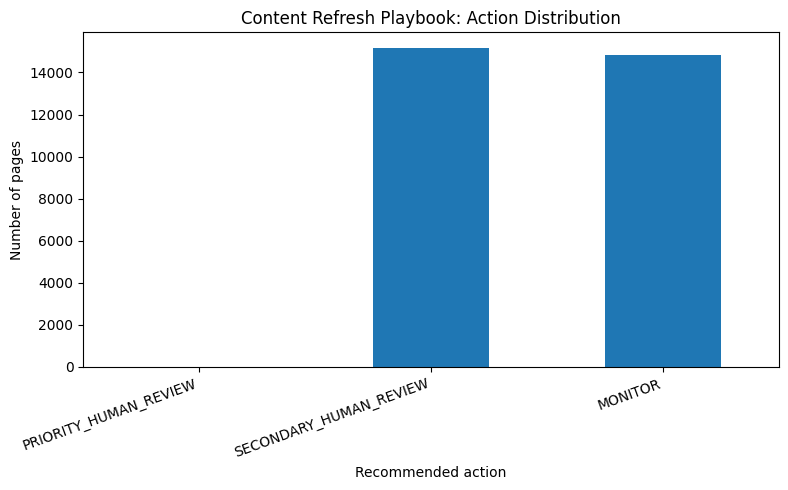

Export complete:
Queue CSV: work/outputs/refresh_action_queue.csv
Metrics JSON: work/outputs/action_playbook_metrics.json
Figure: work/figures/action_distribution.png

Aggregate metrics:
{
  "dataset_rows": 30000,
  "impressions_median": 731.0,
  "ctr_median": 0.07,
  "priority_review_pages": 15,
  "secondary_review_pages": 15151,
  "monitor_pages": 14834,
  "priority_review_pct": 0.05
}


In [5]:

from pathlib import Path
import json
import matplotlib.pyplot as plt

# Create output directories
outputs_dir = Path("work/outputs")
figures_dir = Path("work/figures")

outputs_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Export the ranked queue
queue_path = outputs_dir / "refresh_action_queue.csv"
ranked_queue.to_csv(queue_path, index=False)

# Save aggregate action counts for reporting
action_counts = (
    ranked_queue["recommended_action"]
    .value_counts()
    .reindex(
        [
            "PRIORITY_HUMAN_REVIEW",
            "SECONDARY_HUMAN_REVIEW",
            "MONITOR"
        ],
        fill_value=0
    )
)

summary = {
    "dataset_rows": int(len(ranked_queue)),
    "impressions_median": float(impression_median),
    "ctr_median": float(ctr_median),
    "priority_review_pages": int(action_counts["PRIORITY_HUMAN_REVIEW"]),
    "secondary_review_pages": int(action_counts["SECONDARY_HUMAN_REVIEW"]),
    "monitor_pages": int(action_counts["MONITOR"]),
    "priority_review_pct": round(
        100 * action_counts["PRIORITY_HUMAN_REVIEW"] / len(ranked_queue), 4
    )
}

metrics_path = outputs_dir / "action_playbook_metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

# Plot action distribution
plt.figure(figsize=(8, 5))
action_counts.plot(kind="bar")
plt.title("Content Refresh Playbook: Action Distribution")
plt.xlabel("Recommended action")
plt.ylabel("Number of pages")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

figure_path = figures_dir / "action_distribution.png"
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Export complete:")
print(f"Queue CSV: {queue_path}")
print(f"Metrics JSON: {metrics_path}")
print(f"Figure: {figure_path}")
print("\nAggregate metrics:")
print(json.dumps(summary, indent=2))


In [6]:

from pathlib import Path

expected_files = [
    Path("work/outputs/refresh_action_queue.csv"),
    Path("work/outputs/action_playbook_metrics.json"),
    Path("work/figures/action_distribution.png"),
]

for path in expected_files:
    print("✅" if path.exists() else "❌", path)


✅ work/outputs/refresh_action_queue.csv
✅ work/outputs/action_playbook_metrics.json
✅ work/figures/action_distribution.png


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.